# 01 — EDA C-MAPSS FD001

Exploration du sous-jeu **FD001** : 1 condition de fonctionnement, 1 mode de défaillance (dégradation du HPC).

Objectifs :
1. nombre de moteurs et distribution de leur durée de vie ;
2. évolution de quelques capteurs au fil des cycles ;
3. repérer les capteurs constants / non informatifs.

> Le calcul de la RUL n'est **pas** fait ici (étape suivante).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.data.load import SENSOR_COLUMNS, SETTING_COLUMNS, load_cmapss, load_rul

# Style sobre : grille discrète, traits fins, pas de cadre superflu
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b3ab",
    "axes.labelcolor": "#3d3d3a",
    "axes.titlesize": 11,
    "axes.titleweight": "semibold",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "xtick.color": "#5f5e5a",
    "ytick.color": "#5f5e5a",
    "lines.linewidth": 1.5,
    "legend.frameon": False,
})
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # palette catégorielle, ordre fixe
NEUTRAL = "#b5b3ab"
pd.set_option("display.width", 140)

## 1. Chargement

In [2]:
train = load_cmapss("FD001", "train")
test = load_cmapss("FD001", "test")
rul_test = load_rul("FD001")

print("train :", train.shape, "| test :", test.shape, "| RUL test :", rul_test.shape)
print("valeurs manquantes (train) :", train.isna().sum().sum())
train.head()

train : (20631, 26) | test : (13096, 26) | RUL test : (100,)
valeurs manquantes (train) : 0


,unit_number,time_in_cycles,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 2. Moteurs et durée de vie

Le jeu **train** est *run-to-failure* : chaque moteur est suivi depuis un état sain jusqu'à la panne.
Son dernier cycle = sa durée de vie totale.

In [3]:
lifetime = train.groupby("unit_number")["time_in_cycles"].max().rename("lifetime")

print("moteurs train :", train["unit_number"].nunique())
print("moteurs test  :", test["unit_number"].nunique())
lifetime.describe().round(1)

moteurs train : 100
moteurs test  : 100


count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: lifetime, dtype: float64

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


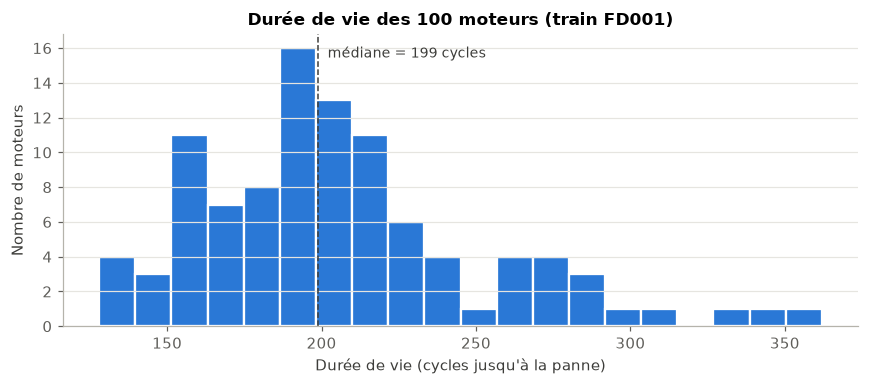

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(lifetime, bins=20, color=SERIES[0], edgecolor="white", linewidth=1.5)
ax.axvline(lifetime.median(), color="#3d3d3a", linestyle="--", linewidth=1)
ax.annotate(f"médiane = {lifetime.median():.0f} cycles", xy=(lifetime.median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color="#3d3d3a", fontsize=9)
ax.set_title("Durée de vie des 100 moteurs (train FD001)")
ax.set_xlabel("Durée de vie (cycles jusqu'à la panne)")
ax.set_ylabel("Nombre de moteurs")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 3. Trajectoires de capteurs

3 moteurs choisis pour couvrir la plage : le plus court, un moteur médian et le plus long.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


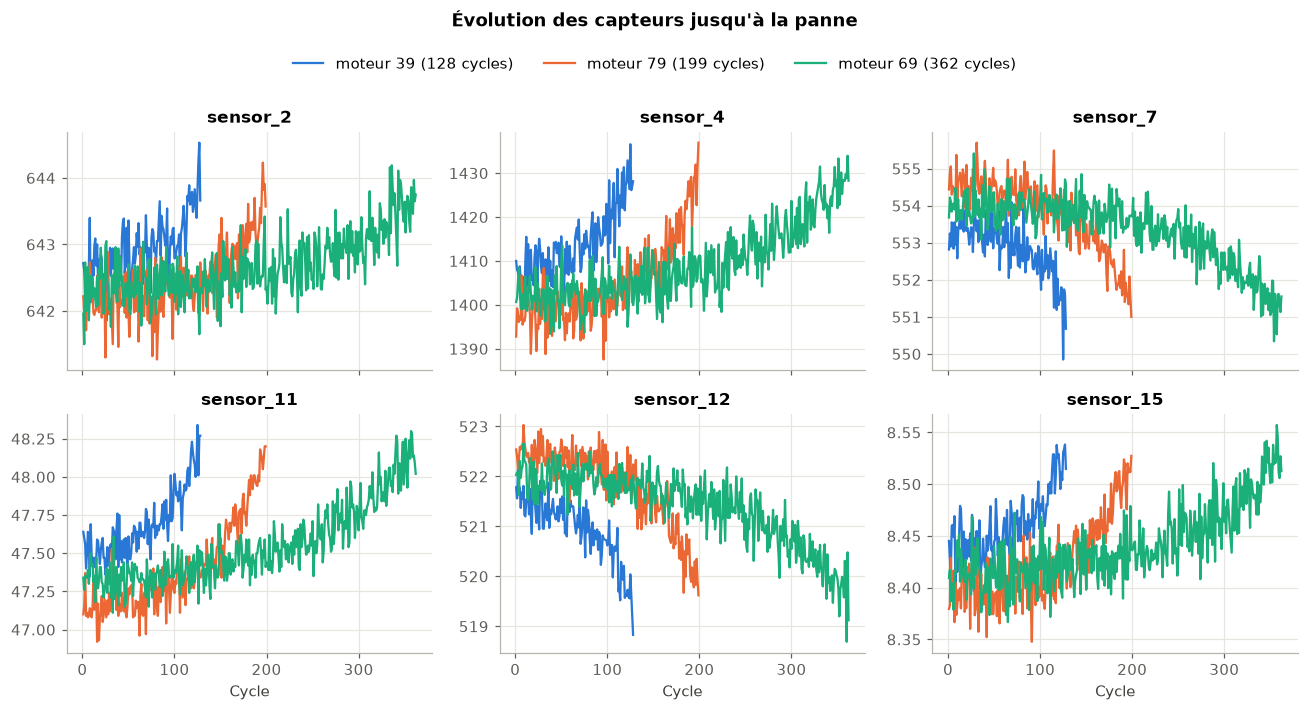

In [5]:
order = lifetime.sort_values()
units = [order.index[0], order.index[len(order) // 2], order.index[-1]]
sensors_to_plot = ["sensor_2", "sensor_4", "sensor_7", "sensor_11", "sensor_12", "sensor_15"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, sensor in zip(axes.flat, sensors_to_plot):
    for color, unit in zip(SERIES, units):
        d = train[train["unit_number"] == unit]
        ax.plot(d["time_in_cycles"], d[sensor], color=color, label=f"moteur {unit} ({lifetime[unit]} cycles)")
    ax.set_title(sensor)
for ax in axes[1]:
    ax.set_xlabel("Cycle")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Évolution des capteurs jusqu'à la panne", y=1.07, fontweight="semibold")
plt.tight_layout()
plt.show()

Lecture : les capteurs dérivent de façon monotone à l'approche de la panne (vers le haut pour 2, 4, 11, 15 ; vers le bas pour 7 et 12).
Le signal est bruité au début puis la tendance s'accélère en fin de vie : c'est la signature de la dégradation.

## 4. Capteurs constants / non informatifs

Deux critères complémentaires :
- **variabilité** : nombre de valeurs distinctes et écart-type ;
- **lien avec l'usure** : corrélation avec le cycle (sur tout le train).

Attention : le coefficient de variation (std / moyenne) seul est trompeur : `sensor_8` et `sensor_13`
ont un CV minuscule (≈ 3e-5) car leur valeur moyenne est grande (~2388), mais ils suivent bien la dégradation.

In [6]:
stats = pd.DataFrame({
    "n_valeurs": train[SENSOR_COLUMNS].nunique(),
    "std": train[SENSOR_COLUMNS].std(),
    "cv": train[SENSOR_COLUMNS].std() / train[SENSOR_COLUMNS].mean().abs(),
    "corr_cycle": train[SENSOR_COLUMNS].corrwith(train["time_in_cycles"]),
})
stats["a_retirer"] = stats["n_valeurs"] <= 2
stats.sort_values("n_valeurs").style.format({"std": "{:.2e}", "cv": "{:.1e}", "corr_cycle": "{:.2f}"})

,n_valeurs,std,cv,corr_cycle,a_retirer
sensor_1,1,0.00e+00,0.0e+00,nan,True
sensor_5,1,5.33e-15,3.6e-16,0.00,True
sensor_16,1,3.47e-18,1.2e-16,0.00,True
sensor_10,1,0.00e+00,0.0e+00,nan,True
sensor_19,1,0.00e+00,0.0e+00,nan,True
sensor_18,1,0.00e+00,0.0e+00,nan,True
sensor_6,2,1.39e-03,6.4e-05,0.11,True
sensor_17,13,1.55e+00,3.9e-03,0.57,False
sensor_8,53,7.10e-02,3.0e-05,0.48,False
sensor_13,56,7.19e-02,3.0e-05,0.48,False


In [7]:
to_drop = stats.index[stats["a_retirer"]].tolist()
useful = [s for s in SENSOR_COLUMNS if s not in to_drop]
print("Capteurs à retirer   :", to_drop)
print("Capteurs informatifs :", useful, f"({len(useful)})")

Capteurs à retirer   : ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Capteurs informatifs : ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21'] (14)


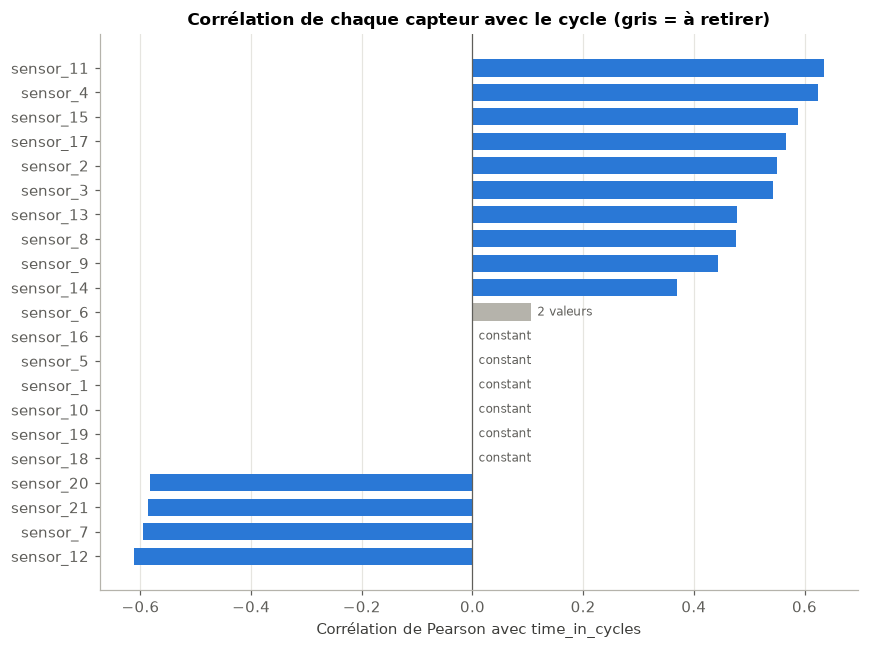

In [8]:
corr = stats["corr_cycle"].fillna(0).sort_values()
colors = [NEUTRAL if s in to_drop else SERIES[0] for s in corr.index]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(corr.index, corr.values, color=colors, height=0.7)
ax.axvline(0, color="#5f5e5a", linewidth=0.8)
ax.set_axisbelow(True)
for s in to_drop:
    ax.annotate("constant" if stats.loc[s, "n_valeurs"] == 1 else "2 valeurs",
                xy=(max(corr[s], 0), list(corr.index).index(s)), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color="#5f5e5a")
ax.set_title("Corrélation de chaque capteur avec le cycle (gris = à retirer)")
ax.set_xlabel("Corrélation de Pearson avec time_in_cycles")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Réglages opérationnels

En FD001 il n'y a qu'une seule condition de vol : les 3 réglages ne varient presque pas.

In [9]:
train[SETTING_COLUMNS].agg(["nunique", "std", "min", "max"]).T

,nunique,std,min,max
op_setting_1,158.0,0.002187,-0.0087,0.0087
op_setting_2,13.0,0.000293,-0.0006,0.0006
op_setting_3,1.0,0.000000,100.0000,100.0000


## 5. Conclusions

- **100 moteurs** en train (run-to-failure) et **100** en test (séries tronquées avant la panne, RUL réelle dans `RUL_FD001.txt`).
- Durée de vie : de **128 à 362 cycles**, médiane ≈ 199 : forte variabilité d'un moteur à l'autre.
- **À retirer (7)** : `sensor_1, 5, 10, 16, 18, 19` (constants) et `sensor_6` (2 valeurs, quasi aucun lien avec l'usure).
- **À garder (14)** : `sensor_2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 17, 20, 21`.
- Réglages opérationnels : inutiles en FD001 (`op_setting_3` constant, les deux autres = bruit autour d'une seule condition).
- `sensor_9` et `sensor_14` ont une tendance plus faible et différente selon les moteurs : à surveiller lors de la sélection de features.